<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [92]:
import random

In [93]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [94]:
len(l)

10000

In [95]:
l[:5]

[4, 7, 4, 7, 10]

In [96]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0291
3     0.0556
4     0.0836
5     0.1115
6     0.1369
7     0.1695
8     0.1391
9     0.1086
10    0.0805
11    0.0573
12    0.0283
Name: count, dtype: float64


<Axes: >

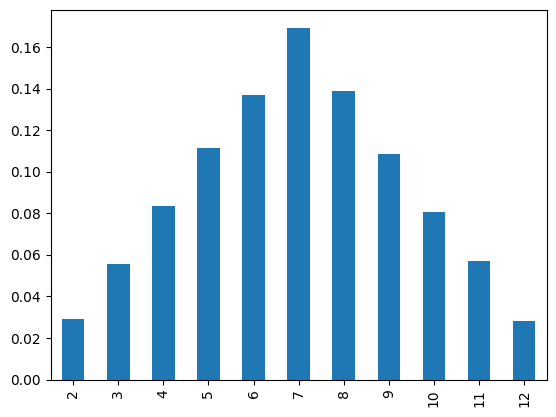

In [97]:
s.plot(kind='bar')

<Axes: >

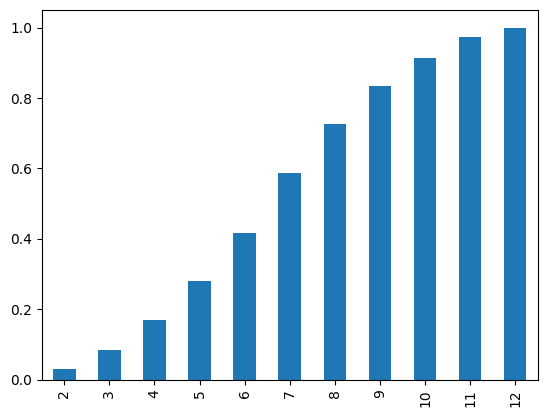

In [98]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [99]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[55.12994872 51.44812916 51.86243874 44.66633256 38.08982046 50.90245878
 46.47546367 47.25589996 53.47332187 46.66991963 47.13268153 51.22218818
 58.76231646 39.77629286 57.92737087 62.04165528 44.22420509 51.48494263
 48.65278447 51.57482503 49.18711015 47.35720234 48.74710935 55.01609147
 48.19985612 41.73120092 56.29374741 45.96310486 49.59398833 35.13362562
 42.34515616 49.8543895  35.60168456 36.45344156 55.77323997 43.95127893
 54.93901349 49.61665405 41.86824152 58.98562072 52.61974037 51.09321847
 51.96007698 52.12848038 45.6220427  46.79014361 53.07743509 51.21143343
 41.23244112 56.52177043 48.42747405 44.27581986 51.15010021 44.64790662
 48.7714017  50.62848046 45.29094241 51.98689936 51.80496567 52.69961139
 52.31378899 46.30599792 47.6375448  44.26080757 49.53596597 53.52221179
 58.94918174 49.84676915 55.72995003 47.50625593 56.78386597 54.92354701
 44.33477134 45.13848561 44.3879402  42.78616021 52.83336912 50.59969262
 50.64359625 44.71502757 59.83653196 50.28248406 43

In [100]:
sample.mean()

np.float64(49.90022021544516)

(array([  4.,  13.,  53., 148., 236., 254., 182.,  79.,  23.,   8.]),
 array([33.06384612, 36.32062318, 39.57740024, 42.8341773 , 46.09095437,
        49.34773143, 52.60450849, 55.86128556, 59.11806262, 62.37483968,
        65.63161675]),
 <BarContainer object of 10 artists>)

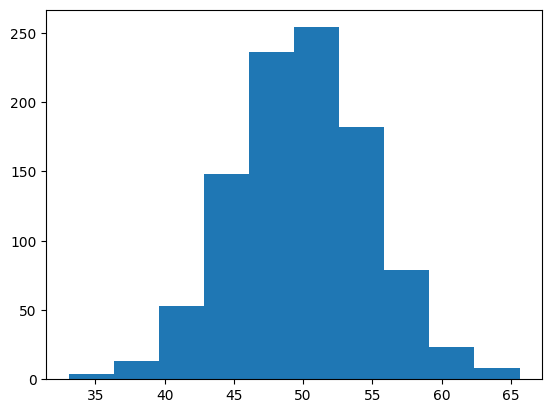

In [101]:
plt.hist(sample,bins=10)

In [102]:
sample_mean=sample.mean()
sample_std=sample.std()

In [103]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [104]:
sample.min()

np.float64(33.06384611598568)

In [105]:
sample.max()

np.float64(65.63161674516014)

In [106]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [107]:
probabilities=[dist.pdf(value) for value in values]

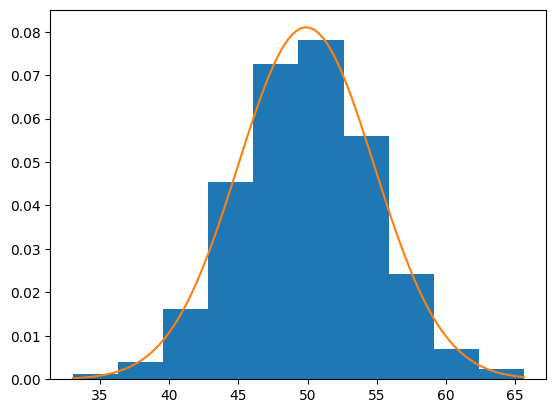

In [108]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_2507/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

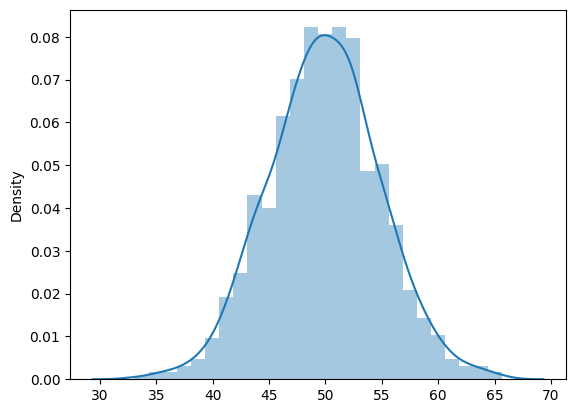

In [109]:
import seaborn as sns
sns.distplot(sample)

KDE

In [110]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [111]:
sample

array([16.72181932, 22.89923167, 19.60294915, 19.54249432,  7.66113082,
       13.41035537, 19.21353801, 33.23514814, 20.55652005, 19.41632131,
       18.84802379, 20.5534569 , 22.74604793, 13.91758498, 18.82998122,
       17.00155753, 27.56938891, 14.44094826, 18.96368696, 17.57027071,
       21.3941002 , 25.86121513, 17.84321686, 13.51806266, 17.09197623,
       22.28453521, 17.95902498, 11.96297586,  7.35348719, 21.72091234,
       21.32780825, 14.51250563, 17.63890862, 27.67560594, 28.00930666,
       14.66107337, 18.11783052, 17.41592531, 26.72193369, 19.68686812,
       16.59582789, 22.31867433, 17.60427797, 26.24089244, 17.49880815,
       23.08627765, 23.42949088, 13.71051596,  6.64913214, 21.2565446 ,
       19.20082586, 11.81358143, 17.29503457, 24.84956167, 20.90284337,
       17.64113406, 22.49666703, 18.77349577, 19.47799835, 21.4400267 ,
       21.24540737, 15.39449393, 16.73263299, 16.21809574, 25.24391855,
       18.44319894, 23.70555346, 20.34447269, 17.16042984, 20.50

(array([ 2.,  3.,  2.,  2.,  1.,  6.,  4.,  8., 18., 14., 14., 33., 22.,
        32., 27., 22., 20., 14., 11., 17., 13., 15.,  4.,  4., 18., 20.,
        23., 22., 34., 48., 50., 40., 39., 65., 49., 57., 57., 44., 30.,
        30., 20., 17.,  9.,  6.,  2.,  7.,  2.,  2.,  0.,  1.]),
 array([ 5.70116802,  6.72317138,  7.74517474,  8.76717811,  9.78918147,
        10.81118483, 11.83318819, 12.85519156, 13.87719492, 14.89919828,
        15.92120164, 16.94320501, 17.96520837, 18.98721173, 20.00921509,
        21.03121846, 22.05322182, 23.07522518, 24.09722854, 25.1192319 ,
        26.14123527, 27.16323863, 28.18524199, 29.20724535, 30.22924872,
        31.25125208, 32.27325544, 33.2952588 , 34.31726217, 35.33926553,
        36.36126889, 37.38327225, 38.40527561, 39.42727898, 40.44928234,
        41.4712857 , 42.49328906, 43.51529243, 44.53729579, 45.55929915,
        46.58130251, 47.60330588, 48.62530924, 49.6473126 , 50.66931596,
        51.69131933, 52.71332269, 53.73532605, 54.75732941,

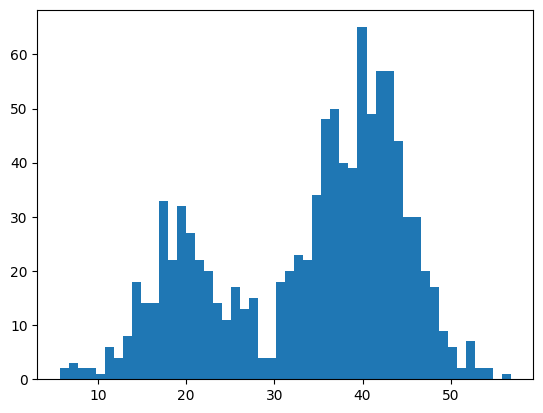

In [112]:
plt.hist(sample,bins=50)

In [113]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [114]:
dataset=sns.load_dataset("iris")

In [115]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

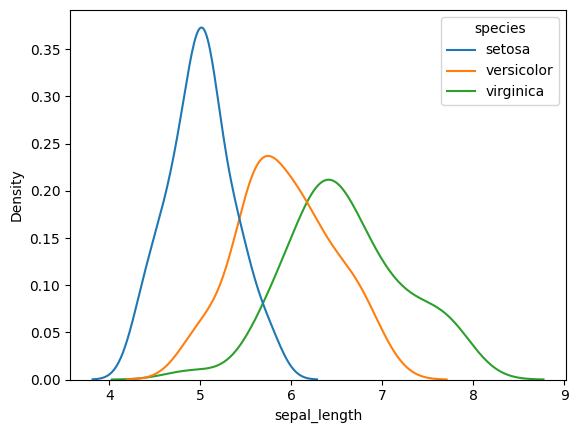

In [116]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

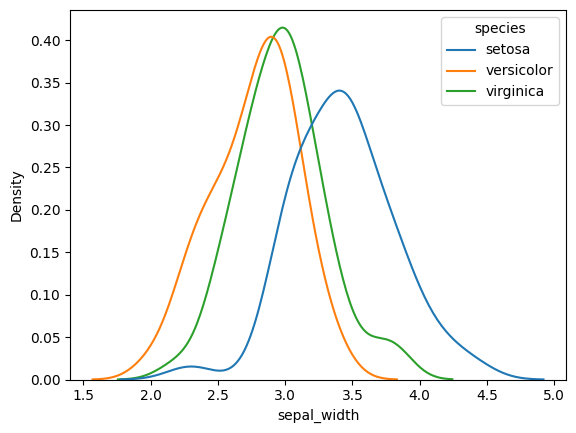

In [117]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

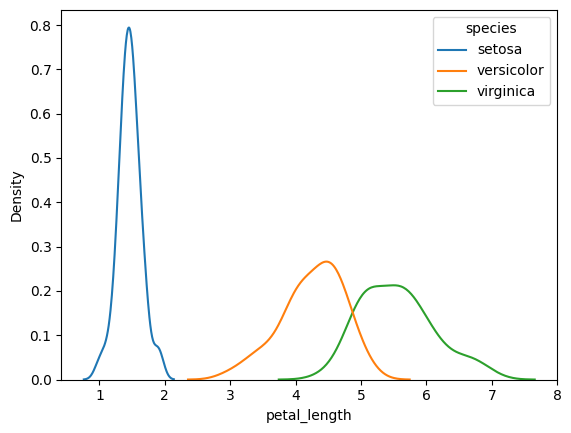

In [118]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

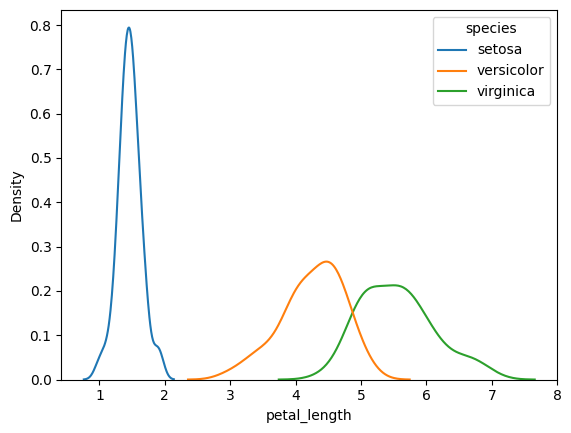

In [119]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [120]:
tips=sns.load_dataset("tips")

In [121]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

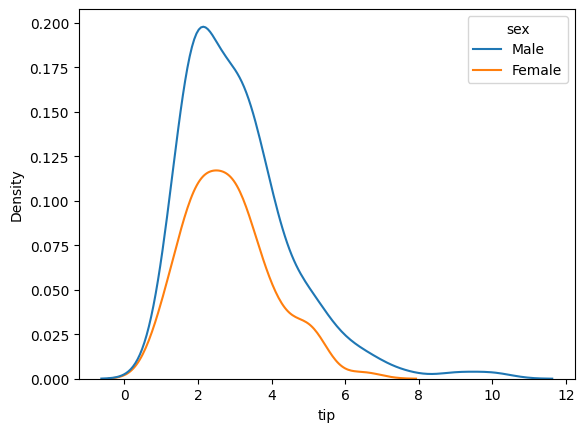

In [122]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

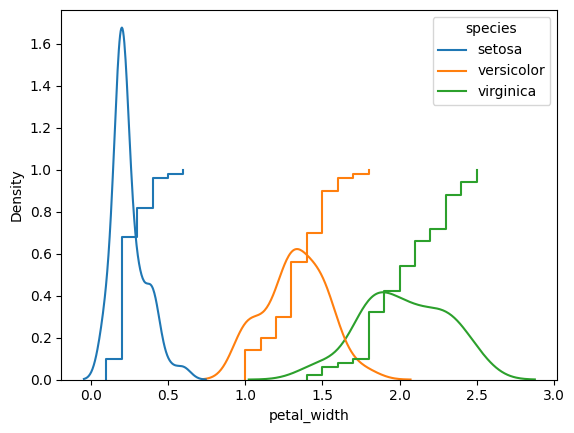

In [123]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [124]:
#contour plots

How to find distribution is normal or not?

In [125]:
iris=sns.load_dataset("iris")

<Axes: xlabel='sepal_length', ylabel='Density'>

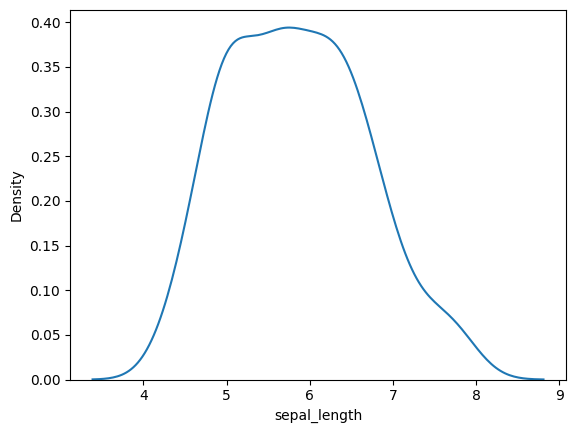

In [126]:
sns.kdeplot(iris["sepal_length"])

In [127]:
temp=sorted(iris['sepal_length'].tolist())

In [128]:
y_quant=[]

for i in range(1,101):
  y_quant.append(np.percentile(temp,i))

In [129]:
samples=np.random.normal(loc=0,scale=1,size=1000)

In [130]:
x_quant=[]

for i in range(1,101):
  x_quant.append(np.percentile(samples,i))

<Axes: >

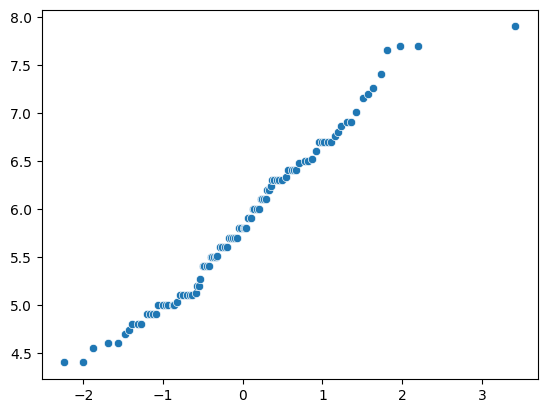

In [131]:
sns.scatterplot(x=x_quant,y=y_quant)

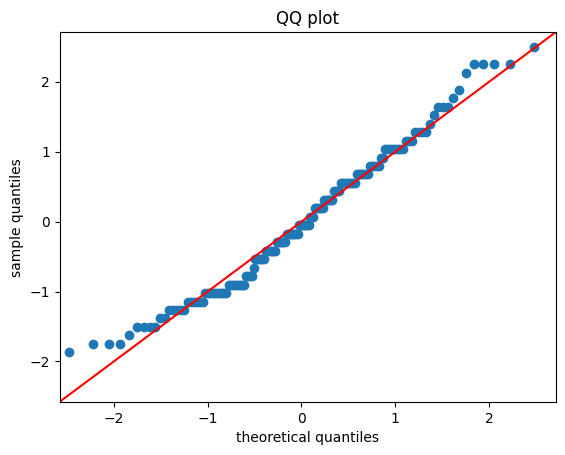

In [132]:
#using statsmodel

import statsmodels.api as sm

#create QQplot of two sets of data
fig=sm.qqplot(iris['sepal_length'],line='45',fit=True)

plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [133]:
import scipy.stats as stats

In [134]:
#genertate a set of random data
x=np.random.uniform(low=0,high=1,size=1000)

(array([ 76.,  87., 108., 106.,  93., 115., 100., 103., 112., 100.]),
 array([3.99723946e-04, 9.99305330e-02, 1.99461342e-01, 2.98992151e-01,
        3.98522960e-01, 4.98053769e-01, 5.97584578e-01, 6.97115387e-01,
        7.96646196e-01, 8.96177005e-01, 9.95707815e-01]),
 <BarContainer object of 10 artists>)

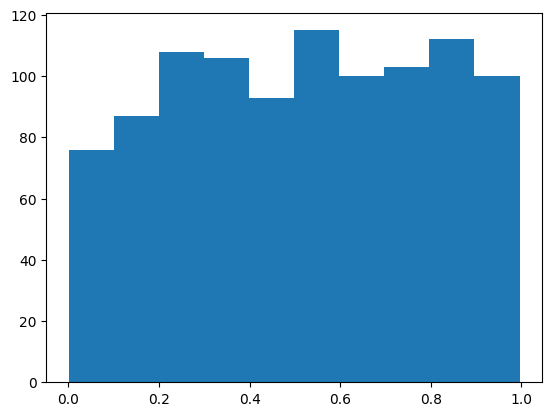

In [135]:
plt.hist(x)

PARETO DISTRIBUTION

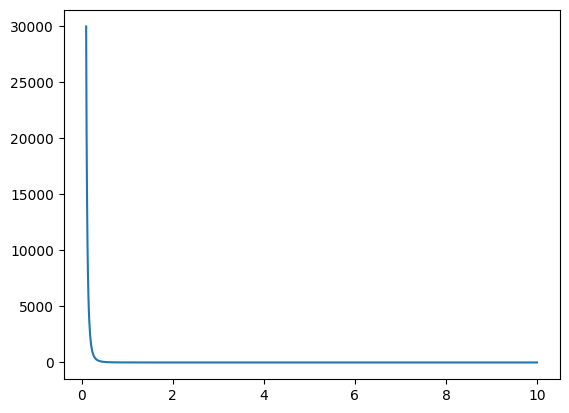

In [136]:
# DEFINE PARAMETERS OF Pareto distribution

alpha=3
xm=1

# create an array of x variables
x=np.linspace(0.1,10,1000)

#calculate teh y values of the pareto distribution
y=alpha*(xm**alpha)/(x**(alpha+1))

plt.plot(x,y)

Text(0.5, 1.0, 'Pareto distribution')

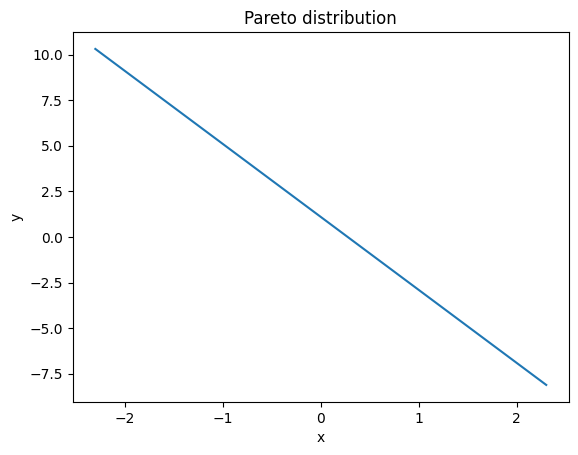

In [137]:
#calculate the log-log plot
plt.plot(np.log(x),np.log(y))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pareto distribution")

In [138]:
alpha =2
xm=1

x=stats.pareto.rvs(b=alpha,scale=xm,size=1000)

(array([935.,  43.,  11.,   4.,   3.,   0.,   2.,   0.,   1.,   1.]),
 array([ 1.00029064,  3.8436192 ,  6.68694776,  9.53027632, 12.37360488,
        15.21693344, 18.060262  , 20.90359056, 23.74691912, 26.59024768,
        29.43357624]),
 <BarContainer object of 10 artists>)

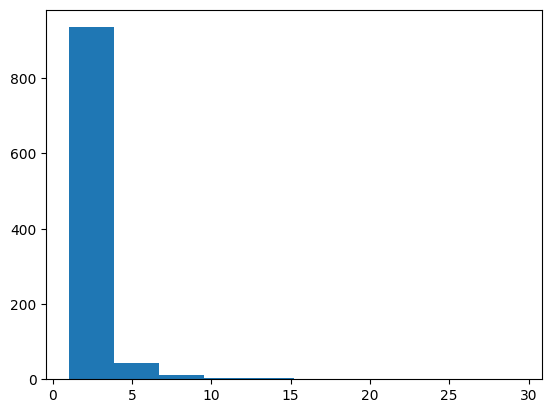

In [139]:
plt.hist(x)

In [140]:
params=stats.pareto.fit(x,floc=0)

#create a pareto distribution object with the fitted parameters
dist=stats.pareto(b=params[0],scale=params[2])

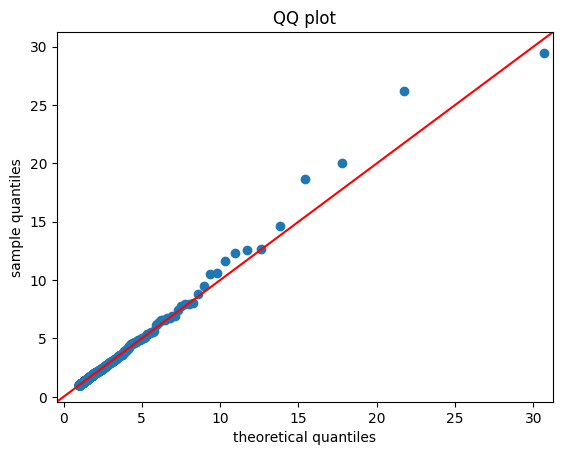

In [141]:
fig=sm.qqplot(x,line='45',dist=dist)
plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [142]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url,usecols=['Battery Age','Cycle Count','Daily Usage Hours'])
battery_csv=df=pd.read_csv(url)
df.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [143]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [144]:
from scipy.stats import stats
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [145]:
df.isnull().sum()
# if missing values use df['column'].fillna(df['column'].mean(),inplace=True)

,0
Battery Age,0
Daily Usage Hours,0
Gaming User,0
Design Capacity,0
Cycle Count,0
CPU Usage,0
GPU Usage,0
Power Consumption,0
Average Temperature,0
Full Charge Capacity,0


In [146]:
x=df.iloc[:,1:5]
y=df.iloc[:,0]

In [147]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

/tmp/ipykernel_2507/1170598051.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Daily Usage Hours'])


Text(0.5, 1.0, 'Daily Usage Hours QQ plot')

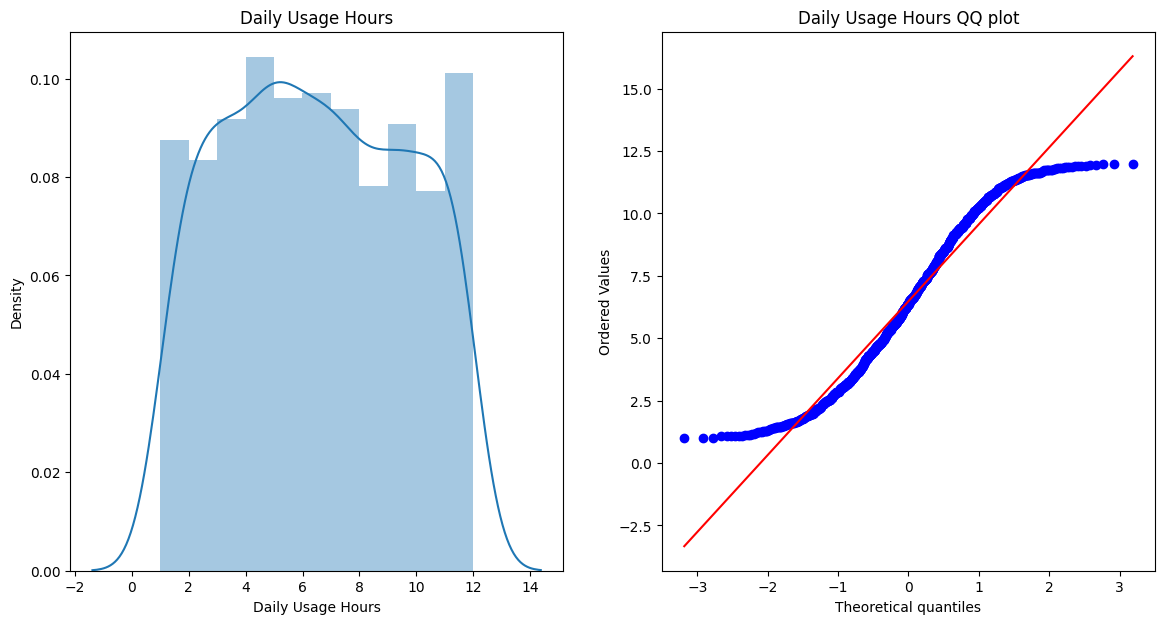

In [148]:
import scipy.stats as stats

plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Daily Usage Hours'])
plt.title("Daily Usage Hours")
plt.subplot(122)
stats.probplot(x_train['Daily Usage Hours'],dist="norm",plot=plt)
plt.title("Daily Usage Hours QQ plot")

Text(0.5, 1.0, 'Cycle Count QQ plot')

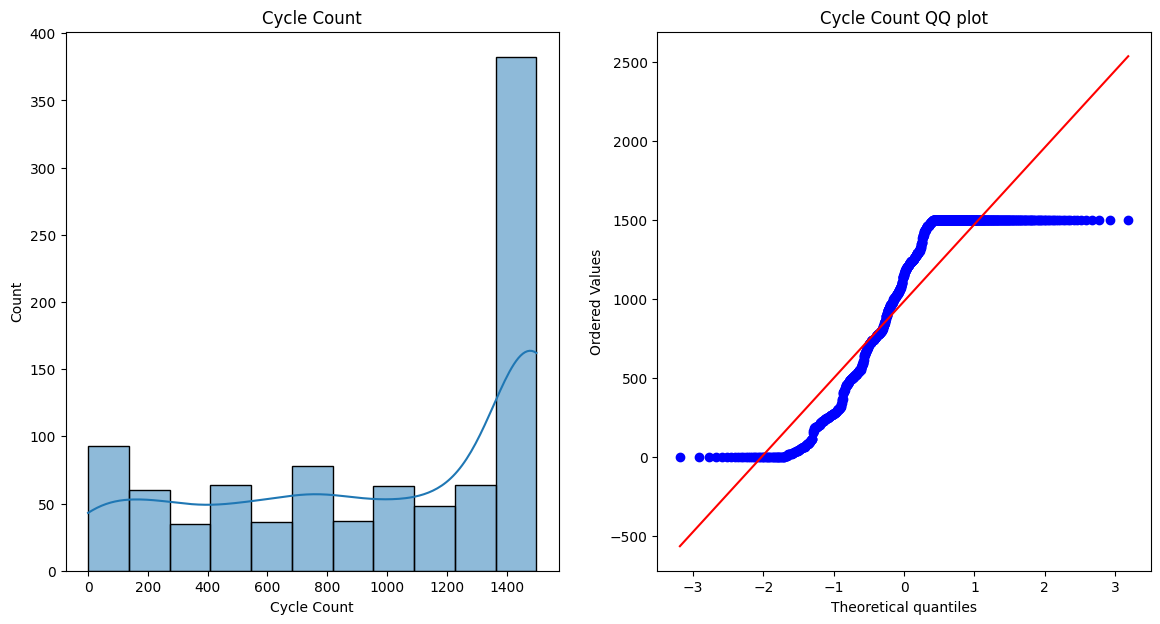

In [149]:
plt.figure(figsize=(14,7))
plt.subplot(121)
sns.histplot(x_train['Cycle Count'], kde=True)
plt.title("Cycle Count")
plt.subplot(122)
stats.probplot(x_train['Cycle Count'],dist="norm",plot=plt)
plt.title("Cycle Count QQ plot")

In [150]:
clf1=LogisticRegression()
clf2=DecisionTreeClassifier()

In [151]:
print(y.value_counts())
print(x.shape, y.shape)

Battery Age
5    145
3    134
9    130
7    126
6    123
0    113
2    112
1    109
4    107
8    101
Name: count, dtype: int64
(1200, 4) (1200,)


In [152]:
print(x.head())
print(y.head())
print(x.nunique())

   Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
0           9.797617            0            57884         1267
1           7.101557            0            63824         1500
2          10.085255            0            79414         1500
3           7.946047            0            61142         1153
4           9.628460            0            50956         1500
0    5
1    9
2    9
3    5
4    7
Name: Battery Age, dtype: int64
Daily Usage Hours    1200
Gaming User             2
Design Capacity      1175
Cycle Count           562
dtype: int64


In [153]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [154]:
clf1.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred=clf1.predict(x_test)
y_pred2=clf2.predict(x_test)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.425
Accuracy DT 0.675


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [155]:
trf=FunctionTransformer(np.log1p)

In [156]:
x_train_transform=trf.fit_transform(x_train)
x_test_transform=trf.transform(x_test)

print(x_train_transform)
print(x_test_transform)

      Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
220            1.572381     0.000000        11.072015     7.313887
479            1.324067     0.000000        10.964398     6.969791
33             2.023224     0.000000        10.832912     6.565265
1179           0.866321     0.000000        11.264477     4.369448
1090           1.463410     0.693147        11.027963     7.313887
...                 ...          ...              ...          ...
1117           1.702189     0.000000        11.251522     6.876265
986            1.084053     0.693147        10.784607     7.313887
1163           1.960635     0.693147        10.876215     7.240650
10             1.487353     0.000000        10.823591     0.000000
347            2.044589     0.000000        11.013781     7.313887

[960 rows x 4 columns]
     Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
273           2.437612     0.000000        11.106550     7.162397
563           2.081121     0.693147     

In [157]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

clf.fit(x_train_transform,y_train)
clf2.fit(x_train_transform,y_train)

y_pred=clf.predict(x_test_transform)
y_pred2=clf2.predict(x_test_transform)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.48333333333333334
Accuracy DT 0.675


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


PDF of binomial ditribution.

[6 2 5 6 4 3 6 7 5 8 8 4 5 1 7 3 6 6 4 4 5 7 5 5 4 5 4 4 1 4 5 6 4 7 5 5 5
 4 6 3 7 5 4 5 3 5 4 5 6 3 4 8 5 4 7 3 4 4 5 4 4 4 6 6 6 6 5 3 4 7 3 5 5 7
 4 4 6 8 5 2 4 8 4 2 8 5 6 7 5 4 7 4 6 1 7 9 9 4 7 4 5 7 5 5 5 7 3 6 5 4 6
 7 6 7 5 4 6 4 6 6 6 7 7 6 4 4 2 4 5 6 5 5 3 6 4 3 6 6 9 3 6 4 5 5 4 6 6 8
 5 6 8 5 6 6 4 4 6 5 3 4 5 6 4 5 5 4 5 2 6 8 5 3 7 6 5 4 6 6 6 5 3 5 6 5 8
 4 6 6 3 4 2 7 6 5 4 8 4 3 5 5 4 7 2 2 4 5 4 6 5 2 8 8 5 5 5 3 6 7 7 3 4 3
 4 6 5 4 4 6 6 7 7 8 8 6 5 6 5 3 6 6 7 4 5 4 4 6 3 4 6 6 4 8 6 5 4 4 4 4 3
 7 9 8 7 7 6 6 5 5 3 8 5 7 7 4 4 5 4 3 7 5 1 6 5 8 6 5 8 5 2 5 6 2 7 4 5 3
 5 5 8 6 4 5 2 3 5 6 3 4 4 4 5 3 4 6 2 6 8 4 6 6 8 4 6 8 4 6 1 4 2 3 6 7 5
 7 6 5 3 6 5 6 5 7 3 5 6 8 6 5 6 4 6 3 3 6 8 3 3 5 4 4 7 4 6 2 5 7 6 7 4 5
 7 2 6 6 3 9 3 8 5 5 5 7 3 4 3 5 4 2 6 4 5 4 2 8 6 6 6 4 5 6 5 5 6 6 4 7 5
 6 6 7 7 5 6 2 4 6 5 5 3 7 7 4 4 5 5 5 5 6 5 6 6 3 6 4 6 5 8 4 6 4 6 5 3 3
 7 5 6 4 6 6 5 5 7 3 5 7 4 7 4 3 4 4 8 6 6 5 7 7 5 7 5 6 6 5 4 5 4 5 6 4 5
 6 3 3 5 2 7 6 3 6 6 6 4 

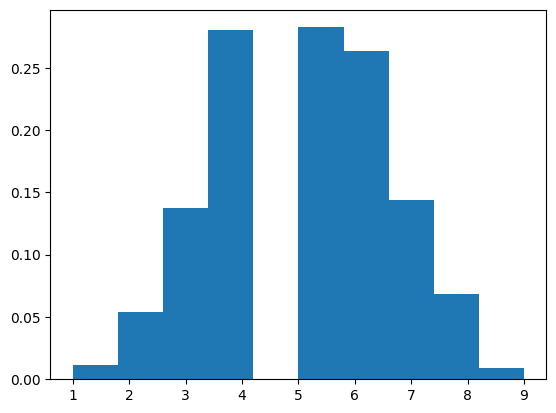

In [158]:
n=10    #number of trials
probability=0.5
binomial_d=np.random.binomial(n=n,p=probability,size=1000)
print(binomial_d)
plt.hist(binomial_d,density=True)
plt.show()
# when probability of success is less left skewed graph and vice versa

Central limit theorem

In [159]:
num_sample=100000
sample_size=300
dist_range=(0,1)

samples=np.random.uniform(dist_range[0],dist_range[1],(num_sample,sample_size))
samples.shape

(100000, 300)

In [160]:
sample_mean=np.mean(samples,axis=1)
sample_mean

array([0.52346419, 0.47887092, 0.49427244, ..., 0.52000738, 0.5338991 ,
       0.51566171])

In [161]:
sample_mean.shape

(100000,)

Text(0.5, 1.0, 'histogram of sample means')

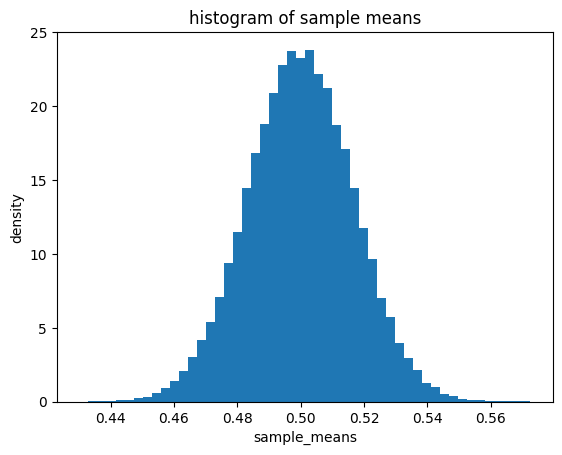

In [162]:
plt.hist(sample_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of sample means")

# greater the number of samples ,gratere is the chances of normal distribution

Different different distributions.

In [163]:
sample_nums=10000
sample_size=50

#poisson distribution parameters
poisson_lambda=5

#gamma distribution parameters
gamma_shape=2
gamma_scale=1

#binomial distribution parameters
binomial_n=10
binomial_p=0.5

# generation
poisson_d=np.random.poisson(lam=poisson_lambda,size=(sample_nums,sample_size))
gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(sample_nums,sample_size))
binomial_d=np.random.binomial(n=binomial_n,p=binomial_p,size=(sample_nums,sample_size))

#calculate means
poisson_mean=np.mean(poisson_d,axis=1)
gamma_mean=np.mean(gamma_d,axis=1)
binomial_mean=np.mean(binomial_d,axis=1)


Text(0.5, 1.0, 'histogram of biomial means')

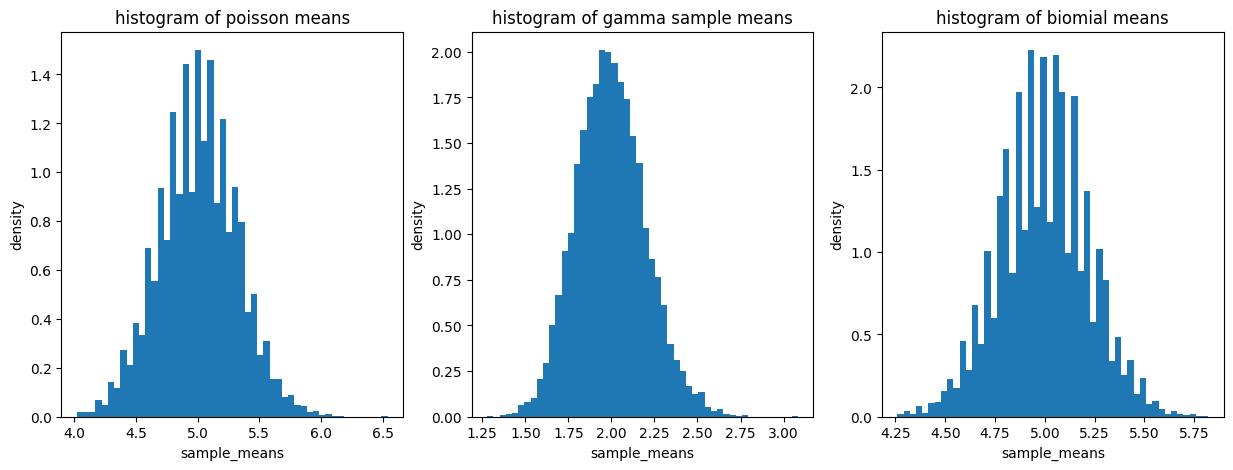

In [164]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1,)
plt.hist(poisson_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of poisson means")

plt.subplot(1,3,2)
plt.hist(gamma_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of gamma sample means")

plt.subplot(1,3,3)
plt.hist(binomial_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of biomial means")

In [165]:
gamma_samples=1000
gamma_size=30

gamma_shape=2
gamma_scale=1

theorotical_mean=gamma_shape*gamma_scale
theorotical_var=(gamma_shape*gamma_scale**2)

gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(gamma_samples,gamma_size))

gamma_means=np.mean(gamma_d,axis=1)
emperical_mean=np.mean(gamma_means)
emperical_var=np.var(gamma_means)

print("Theorotical mean:",theorotical_mean)
print("Theorotical variance:",theorotical_var)
print("Emperical mean:",emperical_mean)
print("Emperical variance:",emperical_var)


Theorotical mean: 2
Theorotical variance: 2
Emperical mean: 1.9998335531016964
Emperical variance: 0.0666209429893809


CASE STUDY

In [166]:
battery_csv.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [167]:
battery_csv.shape

(1200, 11)

In [168]:
d=battery_csv.sample(1200)
d

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
931,3,4.660024,0,48983,651,39.468156,28.658025,69.044466,30.428374,43332.821917,88.023804
383,0,2.845961,0,58739,0,31.736070,21.438466,49.799254,29.070182,58659.764565,100.000000
497,3,1.474101,0,67211,768,22.929157,16.205838,36.098932,29.677030,59185.599166,87.921554
964,5,4.693980,0,63055,1227,35.557118,29.956395,44.161161,30.531905,50392.887464,80.592165
556,1,2.355722,0,54372,239,23.763681,15.167945,51.842697,32.592312,53385.488243,99.867403
...,...,...,...,...,...,...,...,...,...,...,...
513,4,10.762158,0,62064,1011,71.627689,57.609678,93.779903,33.710113,53417.178892,82.193461
8,1,6.952252,0,51696,161,54.529712,33.191792,76.280107,28.872215,50087.394430,96.916534
174,7,10.478314,0,72928,1500,72.098747,49.653014,83.399236,28.719764,58119.159470,78.960946
1027,8,9.599578,0,76541,1500,54.151435,36.688844,58.698203,30.394465,59723.143625,77.158427


In [169]:
d['Daily Usage Hours'].mean()

np.float64(6.43507813125098)

<Axes: ylabel='Density'>

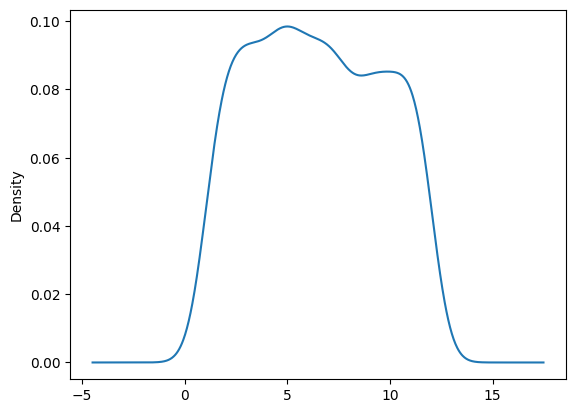

In [170]:
d['Daily Usage Hours'].plot(kind='density')

In [171]:
# taking out 50 samples
df['Daily Usage Hours'].sample(50)

,Daily Usage Hours
859,5.149220
221,3.427162
163,11.356217
102,4.676120
380,11.065017
249,8.097404
1034,3.468213
466,1.145517
57,4.939537
4,9.628460


In [172]:
# converting into pyhton list
df['Daily Usage Hours'].sample(50).values.tolist()

[3.08862862005512,
 1.775892013522522,
 6.063619557070416,
 9.555007010745724,
 8.608921255481576,
 2.699729129895709,
 6.616274496013539,
 4.11612843841835,
 1.132033299999508,
 5.711869806257309,
 1.662496393903272,
 10.43643561869238,
 2.4661268389039046,
 5.605646576604526,
 2.43789055948733,
 11.750122054946225,
 8.667265826047295,
 1.4741011984315646,
 7.938474621898827,
 5.8933767611029495,
 3.3934673392480894,
 8.388797451684669,
 8.101628347642528,
 5.481020766341156,
 3.114837103149011,
 2.691620760645378,
 7.983973250684791,
 7.690325144430913,
 10.761669889073962,
 6.139870956082529,
 11.043456135788416,
 7.904357648746895,
 9.558509371315193,
 9.16521454635642,
 6.990939582178494,
 6.704178575323073,
 8.100877920515746,
 4.278728212870046,
 11.260282329663443,
 9.398674280350336,
 5.403441197902935,
 7.707940377029288,
 2.362306293763992,
 11.690298314580332,
 4.337240979920464,
 3.9761518213679055,
 10.727777707684163,
 8.905899245884225,
 3.1900276192951824,
 7.350887413

In [173]:
samples=[]
for i in range(100):
  samples.append(df['Daily Usage Hours'].sample(50).values.tolist())

In [174]:
samples

[[8.603713301645882,
  10.3230239636021,
  3.4998715891562853,
  8.494103215856772,
  3.6211863760840073,
  6.308613592276728,
  2.168352103473018,
  10.53766200616842,
  3.244964272713363,
  11.484321258335516,
  1.0680220490498633,
  1.6007133353481595,
  11.501329925669758,
  1.1524834950414613,
  8.331741743623384,
  7.348287906266972,
  2.775924546362132,
  2.778640086013856,
  5.249164756600997,
  10.492555856443204,
  6.622032036196378,
  10.997091474885485,
  2.7461043971174046,
  5.9040810480971775,
  10.43643561869238,
  2.3239993383098465,
  1.010377567943942,
  3.747185971522907,
  2.3963885513047,
  3.733938030201686,
  9.856070432452483,
  7.102049836105897,
  1.7017401187895764,
  7.983973250684791,
  10.230096686795727,
  11.424547947707076,
  3.2637381468836386,
  11.869364835500988,
  4.298873522939898,
  7.057265051602207,
  7.15139944945304,
  4.178653774131644,
  8.59355131590802,
  2.613646254166997,
  2.633574598080489,
  10.67906089399716,
  5.620121047252291,
 

In [175]:
samples=np.array(samples)
samples

array([[ 8.6037133 , 10.32302396,  3.49987159, ...,  6.62225002,
         3.46821278,  3.1148371 ],
       [ 1.50143674,  3.62626948,  1.42240965, ..., 10.72052364,
         7.58419293,  3.18494775],
       [ 3.18494775,  1.66249639,  3.86934171, ...,  8.51425714,
         5.2106251 ,  7.43310592],
       ...,
       [ 3.56001184,  6.21739531,  6.58533622, ...,  3.150038  ,
         9.81032594,  6.22245907],
       [ 7.28319102,  6.95397122,  4.14188587, ...,  3.11225706,
         7.6474428 ,  7.75604869],
       [ 6.32590335,  5.07255404,  4.08660895, ...,  2.85106447,
         4.67611986,  6.21739531]])

In [176]:
# calculate mean for each row
sampling_means=samples.mean(axis=1)

In [177]:
sampling_means.mean()

np.float64(6.4367406493072545)

In [178]:
sampling_means.std()/np.sqrt(50)

np.float64(0.06818924029701845)

<Axes: ylabel='Density'>

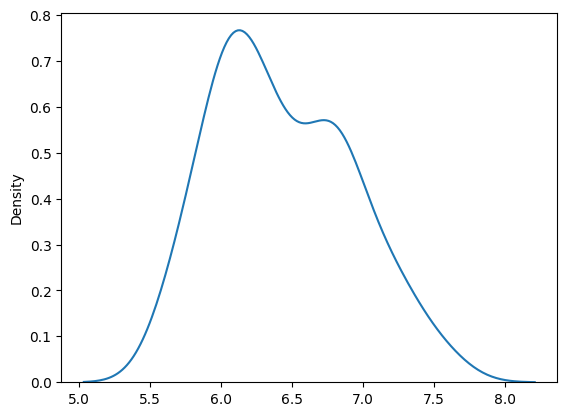

In [179]:
sns.kdeplot(data=sampling_means)

In [180]:
lower_limit=sampling_means.mean()-2*sampling_means.std()/np.sqrt(50)
upper_limit=sampling_means.mean()+2*sampling_means.std()/np.sqrt(50)

print("the range is:",lower_limit,"-",upper_limit)

the range is: 6.300362168713217 - 6.573119129901292
